In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import mysql.connector
import getpass

# Connect to MySQL
conn = mysql.connector.connect(
    host="localhost",
    user="root",         
    password=getpass.getpass("Enter MySQL password: "), 
    database="telco_churn"
)

df = pd.read_sql("SELECT * FROM customer_rfm", conn)
df.head()

C:\Users\gupta\AppData\Local\Temp\ipykernel_15060\2495917157.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM customer_rfm", conn)


,customer_id,tenure_months,monthly_charges,total_charges,contract,payment_method,internet_service,churned,loyalty_tier,engagement_tier,monetary_tier
0,7590-VHVEG,1,29.85,29.85,Month-to-month,Electronic check,DSL,0,Low,Low,Low
1,5575-GNVDE,34,56.95,1889.50,One year,Mailed check,DSL,0,Medium,Medium,Medium
2,3668-QPYBK,2,53.85,108.15,Month-to-month,Mailed check,DSL,1,Low,Medium,Medium
3,7795-CFOCW,45,42.30,1840.75,One year,Bank transfer (automatic),DSL,0,Medium,Medium,Medium
4,9237-HQITU,2,70.70,151.65,Month-to-month,Electronic check,Fiber optic,1,Low,Low,Medium


In [14]:
df.shape
df['churned'].value_counts()

churned
0    5174
1    1869
Name: count, dtype: int64

In [15]:

contingency = pd.crosstab(df['contract'], df['churned'])
print(contingency)

chi2, p_value, dof, expected = chi2_contingency(contingency)
print(f"\nChi-square statistic: {chi2:.2f}")
print(f"p-value: {p_value:.10f}")
print(f"Degrees of freedom: {dof}")

churned            0     1
contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48

Chi-square statistic: 1184.60
p-value: 0.0000000000
Degrees of freedom: 2


In [16]:
contingency2 = pd.crosstab(df['payment_method'], df['churned'])
print(contingency2)

chi2_2, p_value_2, dof_2, expected_2 = chi2_contingency(contingency2)
print(f"\nChi-square statistic: {chi2_2:.2f}")
print(f"p-value: {p_value_2:.10f}")

churned                       0     1
payment_method                       
Bank transfer (automatic)  1286   258
Credit card (automatic)    1290   232
Electronic check           1294  1071
Mailed check               1304   308

Chi-square statistic: 648.14
p-value: 0.0000000000


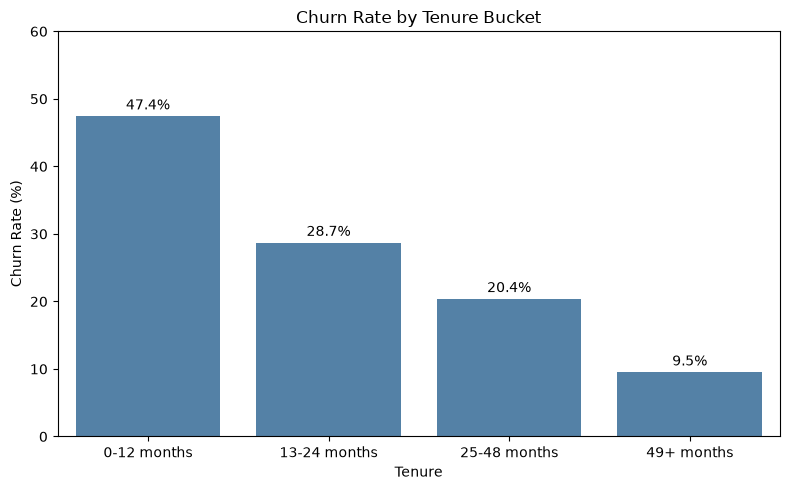

In [17]:

def tenure_bucket(months):
    if months <= 12:
        return '0-12 months'
    elif months <= 24:
        return '13-24 months'
    elif months <= 48:
        return '25-48 months'
    else:
        return '49+ months'

df['tenure_bucket'] = df['tenure_months'].apply(tenure_bucket)


bucket_order = ['0-12 months', '13-24 months', '25-48 months', '49+ months']
churn_by_tenure = df.groupby('tenure_bucket')['churned'].mean().reindex(bucket_order) * 100

plt.figure(figsize=(8, 5))
sns.barplot(x=churn_by_tenure.index, y=churn_by_tenure.values, color='steelblue')
plt.title('Churn Rate by Tenure Bucket')
plt.xlabel('Tenure')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 60)
for i, v in enumerate(churn_by_tenure.values):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.savefig('../notebooks/churn_by_tenure.png', dpi=150)
plt.show()

C:\Users\gupta\AppData\Local\Temp\ipykernel_15060\1612518105.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='churned', y='monthly_charges', data=df, palette=['steelblue', 'indianred'])


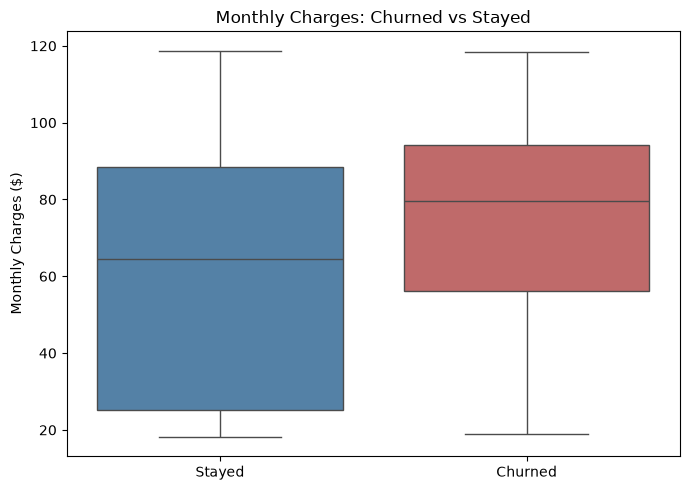

In [18]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='churned', y='monthly_charges', data=df, palette=['steelblue', 'indianred'])
plt.xticks([0, 1], ['Stayed', 'Churned'])
plt.title('Monthly Charges: Churned vs Stayed')
plt.xlabel('')
plt.ylabel('Monthly Charges ($)')
plt.tight_layout()
plt.savefig('../notebooks/monthly_charges_by_churn.png', dpi=150)
plt.show()

In [19]:
df.groupby('churned')['monthly_charges'].agg(['mean', 'median', 'std'])

,mean,median,std
churned,,,
0,61.265124,64.425,31.092648
1,74.441332,79.650,24.666053


In [20]:
df.groupby('churned')['total_charges'].agg(['mean', 'median', 'std'])

,mean,median,std
churned,,,
0,2555.344141,1683.60,2329.456984
1,1531.796094,703.55,1890.822994


In [21]:
df.columns.tolist()

['customer_id',
 'tenure_months',
 'monthly_charges',
 'total_charges',
 'contract',
 'payment_method',
 'internet_service',
 'churned',
 'loyalty_tier',
 'engagement_tier',
 'monetary_tier',
 'tenure_bucket']

In [22]:
conn.close()

In [23]:
df.to_csv('../data/customer_rfm_export.csv', index=False)